In [1]:
import os
import pickle
import numpy as np
import tensorflow as tf
import pandas as pd
import tensorflow_probability as tfp
from tensorflow.keras import datasets, layers, models
import random

from skimage.morphology import skeletonize, thin

from sklearn.model_selection import train_test_split


In [49]:
root = """data\\"""
img_size = (128, 128)
nn_input = (32, 32)
chars = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C',
       'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P',
       'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c',
       'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p',
       'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
learning_rate = 0.0001

In [3]:
src = pd.read_csv("data\english.csv")
# src.head()

In [4]:
def load_img(name):
    loc = root + name.rstrip()
    img = tf.keras.preprocessing.image.load_img(loc, target_size=img_size, color_mode="grayscale")
    img = tf.convert_to_tensor(img, dtype=tf.float32) / 255.0
    img = 1 - img
    return img

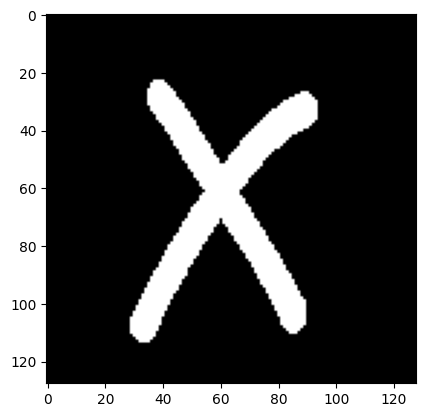

In [5]:
import matplotlib.pyplot as plt

img = load_img("Img/img034-001.png	")
plt.imshow(img, cmap='gray', vmin=0, vmax=1)

Make the image blurry

In [6]:
def randomise(image: tf.Tensor):
    random_values = tf.random.uniform(shape=(8,8,1), minval=0.1, maxval=0.9)
    random_values = tf.reshape(tf.image.resize(random_values, img_size, method="bilinear"), img_size)
    mask = tf.math.greater(image, 0.8)
    return tf.where(mask, random_values, image)

In [7]:
def skeleton(blur):
    sk = thin(blur.numpy(), 1)

    skeletons = [blur, tf.constant(sk, dtype=tf.float32)]

    for j in range(4):
        sk = thin(sk, 1)
        skeletons.append(tf.constant(sk, dtype=tf.float32))

    # Average it out; enh = enhanced
    enh = tf.add_n(skeletons) / len(skeletons)
    return enh

In [8]:
def gaussian_kernel(size: int, mean: float, std: float):
    """Generates a Gaussian kernel to be used for blurring"""
    d = tfp.distributions.Normal(mean, std)
    vals = d.prob(tf.range(start=-size, limit=size+1, dtype=tf.float32))
    gauss_kernel = tf.einsum('i,j->ij', vals, vals)
    gauss_kernel = gauss_kernel / tf.reduce_sum(gauss_kernel)  # Normalize the kernel
    return gauss_kernel[:, :, tf.newaxis, tf.newaxis]

def apply_gaussian_blur(image: tf.Tensor, kernel_size: int, sigma: float):
    kernel = gaussian_kernel(kernel_size, 0., sigma)
    kernel = tf.tile(kernel, [1, 1, image.shape[-1], 1])  # Adjust the kernel to work for each image channel
    image = tf.expand_dims(image, axis=0)  # Add a batch dimension for convolution
    blurred_image = tf.nn.depthwise_conv2d(image, kernel, strides=[1, 1, 1, 1], padding='SAME')
    return tf.squeeze(blurred_image, axis=0)  # Remove the batch dimension

def blur(img):
    blur = tf.reshape(img, [128, 128, 1])
    blur = apply_gaussian_blur(blur, 3, 1.5)
    return tf.reshape(blur, img_size)

In [9]:
def noise(image: tf.Tensor, num_groups: int = 10):
    # Detect black regions (0 value pixels)
    black_pixels = tf.where(image == 0)

    # Randomly select positions to add white pixel groups
    for _ in range(num_groups):
        if len(black_pixels) == 0:
            break  # If no more black pixels are available, stop
        
        # Randomly choose a black pixel location
        random_idx = random.randint(0, len(black_pixels) - 1)
        x, y = black_pixels[random_idx]

        x_d = random.randint(2,4)
        y_d = random.randint(2,4)

        # Define the area to replace with white pixels (within bounds)
        x_start = max(0, x - x_d // 2)
        y_start = max(0, y - y_d // 2)
        x_end = min(image.shape[0], x_start + x_d)
        y_end = min(image.shape[1], y_start + y_d)

        x_d = x_end - x_start
        y_d = y_end - y_start

        # Add white pixels to the selected region
        image = tf.tensor_scatter_nd_update(
            image, 
            indices=tf.convert_to_tensor([[i, j] for i in range(x_start, x_end) for j in range(y_start, y_end)]),
            updates=tf.random.uniform([(x_d * y_d)], minval=0.1, maxval=1.0, dtype=tf.float32)
        )
    
    return image

In [10]:
def ResizeImage(img, new_dim=(32,32)):
    img = tf.reshape(img, [img.shape[0], img.shape[1], 1], tf.image.ResizeMethod.GAUSSIAN)
    nn_shape = [new_dim[0], new_dim[1], 1]
    return tf.reshape(tf.image.resize(img, new_dim), nn_shape)

In [11]:
final = ResizeImage(noise(skeleton(randomise(blur(img)))), nn_input)

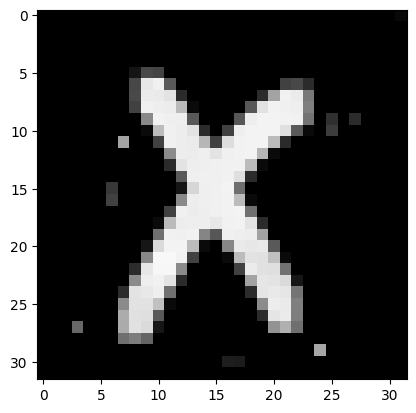

In [12]:
plt.imshow(final, cmap='gray', vmin=0, vmax=1)

---------

In [13]:
imgs = []
labels = []

for i in range(len(src)):
    x = load_img(src.iloc[i]['image'])
    x = ResizeImage(noise(skeleton(randomise(blur(x)))), nn_input)
    imgs.append([x])

    y = src.iloc[i]['label']
    labels.append(chars.index(y))

    # plt.imshow(x, cmap='gray', vmin=0, vmax=1)

    # print(y)

In [14]:
x_train, x_test, y_train, y_test = train_test_split(imgs, labels, test_size=0.1, random_state=2)

In [15]:
x_train = tf.concat(x_train, 0)
x_test = tf.concat(x_test, 0)
y_train = tf.constant(y_train, dtype=tf.int16)
y_test = tf.constant(y_test, dtype=tf.int16)

In [16]:
x_test = tf.reshape(x_test, (x_test.shape[0], nn_input[0] * nn_input[1]))

In [17]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

datagen.fit(x_train)

In [18]:
# # Initial model design

# # Here's the convnet
# model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 1)))
# model.add(layers.MaxPooling2D((2, 2)))
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# model.add(layers.MaxPooling2D((4, 4)))
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# # This is the dense net that parses the output from the convnet
# model.add(layers.Flatten())
# model.add(layers.Dense(256, activation='sigmoid'))
# model.add(layers.Dense(len(chars), activation='sigmoid'))


In [74]:
model = tf.keras.Sequential()

model.add(tf.keras.Input(shape=(nn_input[0] * nn_input[1],)))
model.add(layers.Dense(70, activation="sigmoid"))
model.add(layers.Dense(60, activation="sigmoid"))
model.add(layers.Dense(50, activation="sigmoid"))
model.add(layers.Dense(40, activation="sigmoid"))
model.add(layers.Dense(50, activation="sigmoid"))
model.add(layers.Dense(60, activation="sigmoid"))
model.add(layers.Dense(len(chars), activation="softmax"))

model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_28 (Dense)            (None, 70)                71750     
                                                                 
 dense_29 (Dense)            (None, 60)                4260      
                                                                 
 dense_30 (Dense)            (None, 50)                3050      
                                                                 
 dense_31 (Dense)            (None, 40)                2040      
                                                                 
 dense_32 (Dense)            (None, 50)                2050      
                                                                 
 dense_33 (Dense)            (None, 60)                3060      
                                                                 
 dense_34 (Dense)            (None, 62)               

In [75]:
# This is to load the weights from the checkpoints

# This code is always to be commented
checkpoint = tf.train.Checkpoint(model)
checkpoint.restore(os.getcwd() + "/Checkpoints/" + "PNN").expect_partial()

In [104]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy', 'mean_squared_error'])

batch_size = 100
num_batches = 10
epochs = 500

# Create the training data
data_gen = datagen.flow(x_train, y_train, batch_size=batch_size)

train_data = []
train_label = []

for i in range(num_batches):
    temp = next(data_gen)
    train_data.append(tf.reshape(temp[0], (temp[0].shape[0], nn_input[0] * nn_input[1])))
    # This is the tranformation that needs to be done to enable the new network to work:
    # The shape is transformed so that the image is laid out from 2D to 1D

    train_label.append(temp[1])

train_data = tf.concat(train_data, 0)
train_label = tf.concat(train_label, 0)
# End of training data creation

# The below code is used if you want to pick up training from where you stopped
# Create a callback that saves the model's weights
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=os.getcwd() + "/Checkpoints/" + "PNN",
                                                 save_weights_only=True,
                                                 verbose=1,
                                                 monitor="accuracy",
                                                 save_best_only=True,
                                                 mode="max",)


Epoch 1/5000
 1/10 [==>...........................] - ETA: 20s - loss: 8.9790 - accuracy: 0.0300 - mean_squared_error: 1239.2200
Epoch 1: accuracy improved from -inf to 0.02800, saving model to c:\Work\Programming\Hackathons\Reprose\Notes generation\DeploymentFiles/Checkpoints\PNN
10/10 [==============================] - 3s 54ms/step - loss: 8.9297 - accuracy: 0.0280 - mean_squared_error: 1243.3917 - val_loss: 8.3948 - val_accuracy: 0.0235 - val_mean_squared_error: 1312.3765
Epoch 2/5000
 1/10 [==>...........................] - ETA: 0s - loss: 9.2973 - accuracy: 0.0100 - mean_squared_error: 1328.1564
Epoch 2: accuracy did not improve from 0.02800
10/10 [==============================] - 0s 10ms/step - loss: 8.7036 - accuracy: 0.0270 - mean_squared_error: 1243.3916 - val_loss: 8.2756 - val_accuracy: 0.0293 - val_mean_squared_error: 1312.3767
Epoch 3/5000
10/10 [==============================] - ETA: 0s - loss: 8.5430 - accuracy: 0.0280 - mean_squared_error: 1243.3915
Epoch 3: accuracy d

(0.0, 1.0)

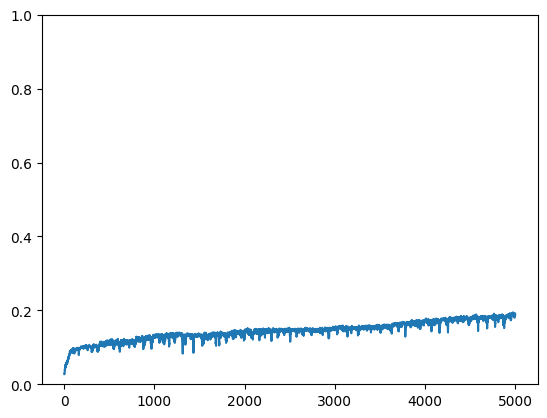

In [105]:
# The below is how you are to apply the data augumentation method:
# Train the model with data augmentation
history = model.fit(
    train_data,
    train_label,
    batch_size=batch_size,
    epochs=5000,
    validation_data=(x_test, y_test),
    callbacks=[cp_callback],
) # Tune these parameters later

plt.plot(history.history['accuracy'])
plt.ylim(0, 1)

In [106]:
data = model.evaluate(x_test, y_test, verbose=2)
print("Restored model, accuracy: {:5.2f}%".format(100 * data[1]))

11/11 - 0s - loss: 5.4677 - accuracy: 0.0323 - mean_squared_error: 1312.3741 - 124ms/epoch - 11ms/step
Restored model, accuracy:  3.23%


11/11 [==============================] - 0s 3ms/step
L
f


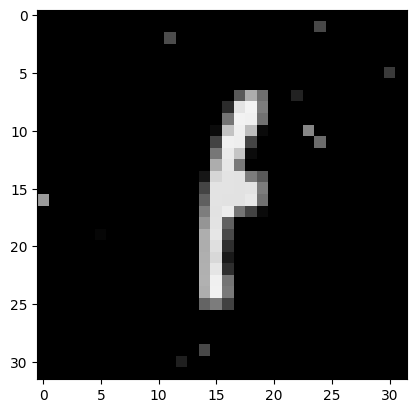

In [96]:
image_see = 82

y_pred = model.predict(x_test)

print(chars[tf.math.argmax(y_pred[image_see])])
print(chars[y_test[image_see].numpy()])
plt.imshow(tf.reshape(x_test[image_see], [32, 32, 1]), cmap='gray', vmin=0, vmax=1)

In [103]:
# This is to save weights
model.save_weights(os.getcwd() + "/Checkpoints/" + "PNN")

tf.Tensor(
[0.4757525  0.6666356  0.65608037 0.2808514  0.741683   0.58097076
 0.7319642  0.85219043 0.20418616 0.01864642 0.5237762  0.9347604
 0.66847414 0.31280202 0.832248   0.7526114  0.17010683 0.00678308
 0.28275913 0.25437734 0.9329179  0.8710812  0.00774535 0.27636218
 0.80402184 0.05282016 0.94382125 0.87906796 0.9025951  0.6028383
 0.45608187 0.09211763 0.95371383 0.40434608 0.91540253 0.9022091
 0.5915055  0.6928534  0.41654375 0.14200598 0.02294357 0.53664947
 0.8930625  0.9437144  0.5115443  0.12543964 0.5985601  0.11470743
 0.03355322 0.92056763 0.5947654  0.9151086  0.8193301  0.39917445
 0.9484302  0.7905994  0.09072971 0.9624338  0.2616036  0.3775129
 0.4170991  0.90038854], shape=(62,), dtype=float32)
v



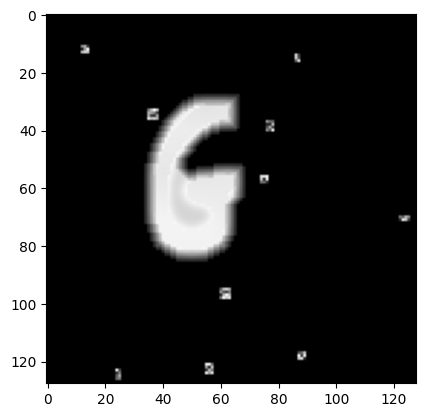

In [63]:
i = 135

y = model(tf.reshape(x_test[i], [1,128,128,1]))
print(y[0])
print(chars[tf.argmax(y[0])])

print()
plt.imshow(x_test[i], cmap='gray', vmin=0, vmax=1)

Trainsition probabilities

In [39]:
loc = "data//" + "Articles.bin" # To train more change the Articles.bin file by swapping it with freshly generated articles. Use the generator in diplomacy software.

with open(loc, "rb") as f:
    articles = pickle.load(f)

In [40]:
df2 = pd.read_csv('data//TransitionModel.csv', header=None) # read data from the csv file

In [41]:
words = []

for key in articles.values():
    text = key.replace('\n', ' ')
    split_text = text.split()
    words += split_text

In [ ]:
# Update the values in the dataframe based on words

for w in words:
    for c in range(len(w) - 1):
        try:
            prev = chars.index(w[c])
            next = chars.index(w[c + 1])
            df2.loc[prev, next] += 1
        except ValueError:
            pass

In [ ]:
df2.to_csv('data//TransitionModel.csv', index=False, header=False) # store data into the csv file
del df2

In [ ]:
def GetProbs(prev): # The input is the index of the character, not the character itself

    df2 = pd.read_csv('data//TransitionModel.csv', header=None)

    sum = df2.loc[prev].sum()

    return df2.loc[prev].tolist() / sum

In [ ]:
len(GetProbs(5))

62

In [ ]:
a = tf.constant(GetProbs(5))
b = tf.constant(GetProbs(6))

tf.math.multiply(a,b)

<tf.Tensor: shape=(62,), dtype=float64, numpy=
array([1.94503794e-01, 2.83651367e-03, 1.98924335e-03, 2.83651367e-03,
       2.35762175e-03, 2.21027039e-03, 9.20945996e-04, 6.63081117e-04,
       1.47351359e-04, 4.42054078e-04, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.47351359e-04, 3.68378398e-05, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.47351359e-04,
       0.00000000e+00, 0.00000

In [17]:
chars.index('A')

10